# ETTデータセット EDA（Google Colab）

ETTh1/2（1時間間隔）とETTm1/2（15分間隔）を比較し、ETTh1を中心にOTの時系列・周期性・負荷との関係を探索します。Google Driveに4つのCSVを置き、上から順に実行してください。相関やラグ相関は関連性の確認であり、因果関係を示すものではありません。

## 1. Colab ランタイム情報の確認
Pythonのバージョン、CPU、メモリ、GPU/TPUを表示します。

In [60]:
import os
import platform
import shutil
import subprocess

print("Python:", platform.python_version())
print("CPU count:", os.cpu_count())
try:
    memory_bytes = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES")
    print(f"Approx. memory: {memory_bytes / (1024 ** 3):.1f} GiB")
except (ValueError, OSError, AttributeError):
    print("Memory information unavailable")

if shutil.which("nvidia-smi"):
    gpu_info = subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True).stdout.strip()
    print("GPU:", gpu_info or "not detected")
else:
    print("GPU: not detected")
print("TPU:", "detected" if os.environ.get("COLAB_TPU_ADDR") else "not detected")

Python: 3.13.18
CPU count: 2
Approx. memory: 12.7 GiB
GPU: not detected
TPU: not detected


## 2. 必要パッケージのインストール
Colabの環境に必要な可視化・時系列分解パッケージを入れます。

In [61]:
%pip -q install seaborn==0.13.2 statsmodels==0.14.4

## 3. Google Drive のマウント

In [62]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 4. 作業ディレクトリとパス設定
データの読み込み元は`/content/drive/Othercomputers/マイ Mac/assignment-main/data`に固定しています。ファイル選択や別フォルダーの自動検索は行いません。

In [63]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

MYDRIVE = Path("/content/drive/Othercomputers/マイ Mac/")
DRIVE_ROOT = MYDRIVE / "assignment-main"
OUTPUT_DIR = DRIVE_ROOT / "eda_output"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
for directory in (OUTPUT_DIR, FIGURE_DIR, TABLE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["axes.titleweight"] = "bold"

DATA_DIR = Path("/content/drive/Othercomputers/マイ Mac/assignment-main/data")
expected_csvs = ["ETTh1.csv", "ETTh2.csv", "ETTm1.csv", "ETTm2.csv"]
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"固定データフォルダーが見つかりません: {DATA_DIR}\n"
        "Google Driveのマウント状態とフォルダー名を確認してください。"
    )
missing_csvs = [filename for filename in expected_csvs if not (DATA_DIR / filename).is_file()]
if missing_csvs:
    raise FileNotFoundError(
        f"{DATA_DIR} にCSVがありません: {missing_csvs}"
    )

print("読み込み元 DATA_DIR:", DATA_DIR)
print("出力先 OUTPUT_DIR:", OUTPUT_DIR)
print("確認済みCSV:", expected_csvs)

読み込み元 DATA_DIR: /content/drive/Othercomputers/マイ Mac/assignment-main/data
出力先 OUTPUT_DIR: /content/drive/Othercomputers/マイ Mac/assignment-main/eda_output
確認済みCSV: ['ETTh1.csv', 'ETTh2.csv', 'ETTm1.csv', 'ETTm2.csv']


In [64]:
REQUIRED_COLUMNS = ["date", "HUFL", "HULL", "MUFL", "MULL", "LUFL", "LULL", "OT"]
DATASET_NAMES = ["ETTh1", "ETTh2", "ETTm1", "ETTm2"]


def load_ett_csv(dataset_name):
    csv_path = DATA_DIR / f"{dataset_name}.csv"
    frame = pd.read_csv(csv_path)
    missing_columns = sorted(set(REQUIRED_COLUMNS) - set(frame.columns))
    if missing_columns:
        raise ValueError(f"{dataset_name}: 必須列がありません: {missing_columns}")

    frame = frame[REQUIRED_COLUMNS].copy()
    frame["date"] = pd.to_datetime(frame["date"], errors="coerce")
    frame = frame.dropna(subset=["date"]).sort_values("date").set_index("date")
    frame[REQUIRED_COLUMNS[1:]] = frame[REQUIRED_COLUMNS[1:]].apply(
        pd.to_numeric, errors="coerce"
    )
    return frame


datasets = {name: load_ett_csv(name) for name in DATASET_NAMES}
for name, frame in datasets.items():
    print(f"{name}: {len(frame):,} rows | {frame.index.min()} -> {frame.index.max()}")

ETTh1: 17,420 rows | 2016-07-01 00:00:00 -> 2018-06-26 19:00:00
ETTh2: 17,420 rows | 2016-07-01 00:00:00 -> 2018-06-26 19:00:00
ETTm1: 69,680 rows | 2016-07-01 00:00:00 -> 2018-06-26 19:45:00
ETTm2: 69,680 rows | 2016-07-01 00:00:00 -> 2018-06-26 19:45:00


## 6. 前処理パイプラインの実装
欠損・重複時刻・記録間隔を点検します。モデル評価に備え、時系列順のtrain/valid/test分割関数も用意します。欠損値はEDA段階では補完しません。

In [65]:
def chronological_split(frame, train_ratio=0.70, valid_ratio=0.15):
    if train_ratio <= 0 or valid_ratio <= 0 or train_ratio + valid_ratio >= 1:
        raise ValueError("train_ratio と valid_ratio は正で、合計1未満にしてください")
    train_end = int(len(frame) * train_ratio)
    valid_end = int(len(frame) * (train_ratio + valid_ratio))
    return frame.iloc[:train_end], frame.iloc[train_end:valid_end], frame.iloc[valid_end:]


quality_rows = []
summary_rows = []
for name, frame in datasets.items():
    deltas = frame.index.to_series().diff().dropna()
    median_cadence = deltas.median() if not deltas.empty else pd.NaT
    quality_rows.append({
        "dataset": name,
        "rows": len(frame),
        "start": frame.index.min(),
        "end": frame.index.max(),
        "median_cadence": median_cadence,
        "duplicate_timestamps": int(frame.index.duplicated().sum()),
        "missing_cells": int(frame.isna().sum().sum()),
        "missing_OT": int(frame["OT"].isna().sum()),
        "non_median_intervals": int((deltas != median_cadence).sum()) if not deltas.empty else 0,
    })
    summary_rows.append({
        "dataset": name,
        "OT_mean": frame["OT"].mean(),
        "OT_std": frame["OT"].std(),
        "OT_min": frame["OT"].min(),
        "OT_median": frame["OT"].median(),
        "OT_max": frame["OT"].max(),
    })

quality_report = pd.DataFrame(quality_rows).set_index("dataset")
dataset_summary = pd.DataFrame(summary_rows).set_index("dataset")
display(quality_report)
display(dataset_summary.round(3))

train_df, valid_df, test_df = chronological_split(datasets["ETTh1"])
print(f"ETTh1 時系列分割: train={len(train_df):,}, valid={len(valid_df):,}, test={len(test_df):,}")

,rows,start,end,median_cadence,duplicate_timestamps,missing_cells,missing_OT,non_median_intervals
dataset,,,,,,,,
ETTh1,17420,2016-07-01,2018-06-26 19:00:00,0 days 01:00:00,0,0,0,0
ETTh2,17420,2016-07-01,2018-06-26 19:00:00,0 days 01:00:00,0,0,0,0
ETTm1,69680,2016-07-01,2018-06-26 19:45:00,0 days 00:15:00,0,0,0,0
ETTm2,69680,2016-07-01,2018-06-26 19:45:00,0 days 00:15:00,0,0,0,0


,OT_mean,OT_std,OT_min,OT_median,OT_max
dataset,,,,,
ETTh1,13.325,8.567,-4.080,11.396,46.007
ETTh2,26.609,11.888,-2.647,26.577,58.877
ETTm1,13.321,8.565,-4.221,11.396,46.007
ETTm2,26.610,11.887,-2.647,26.577,58.877


ETTh1 時系列分割: train=12,194, valid=2,613, test=2,613


## 7. 主要処理の実行（EDA）
4データセットのOT分布を比較し、ETTh1のOT推移・負荷変数・時間帯パターン・相関を確認します。

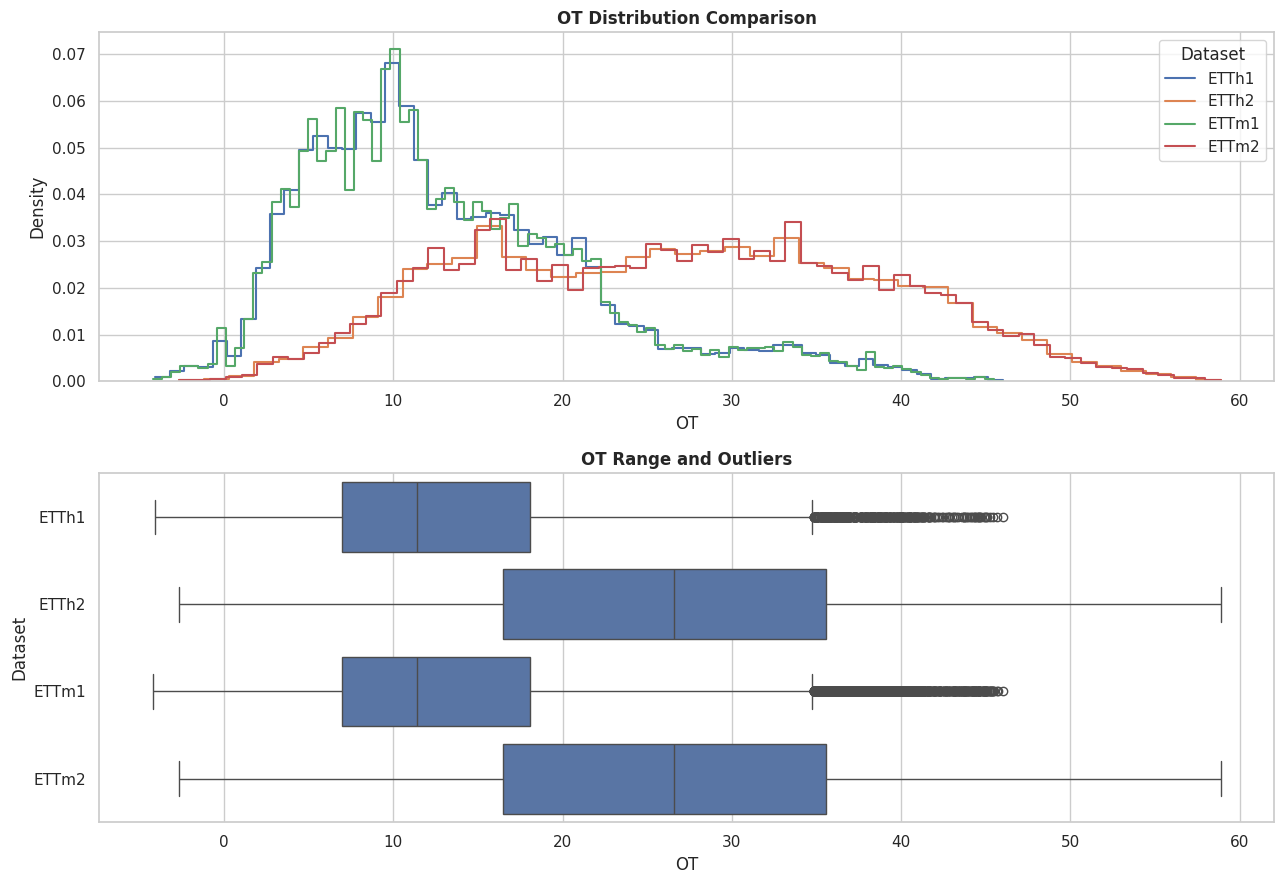

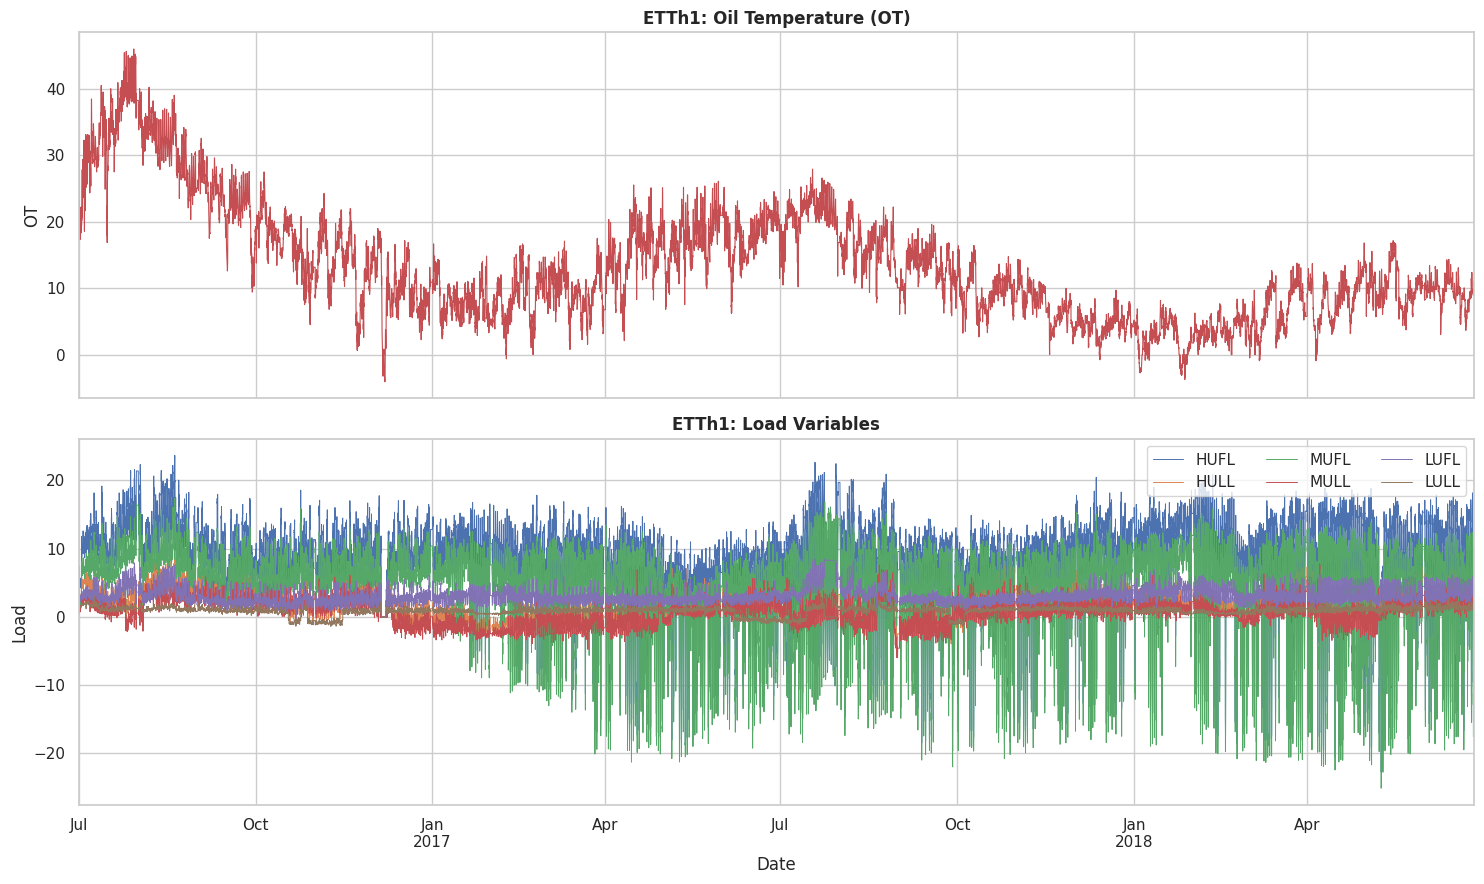

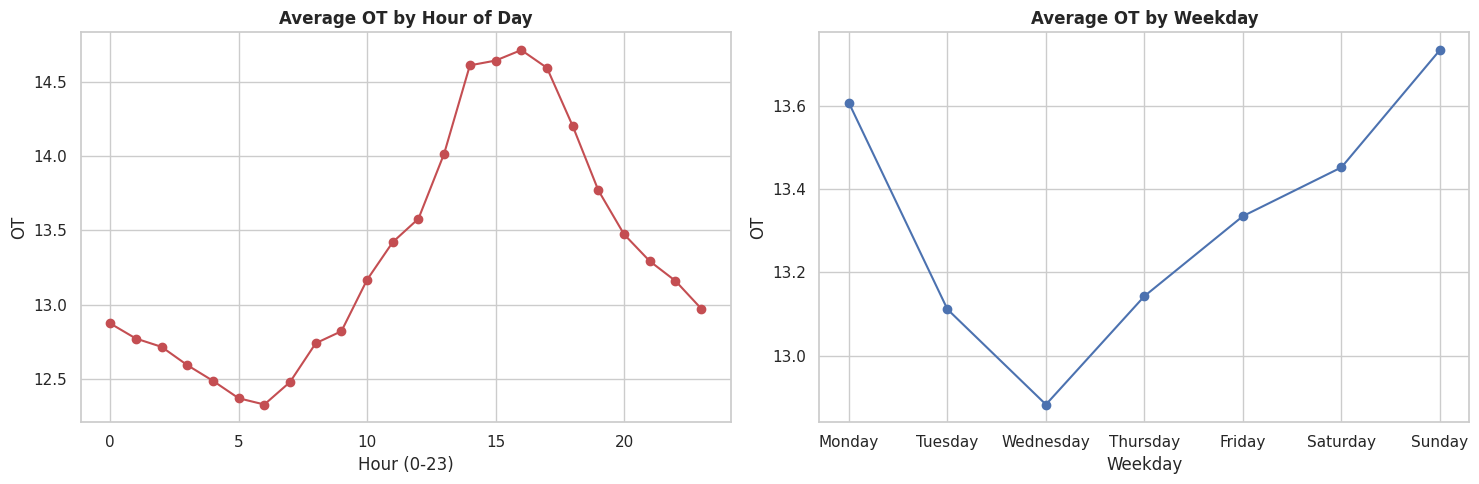

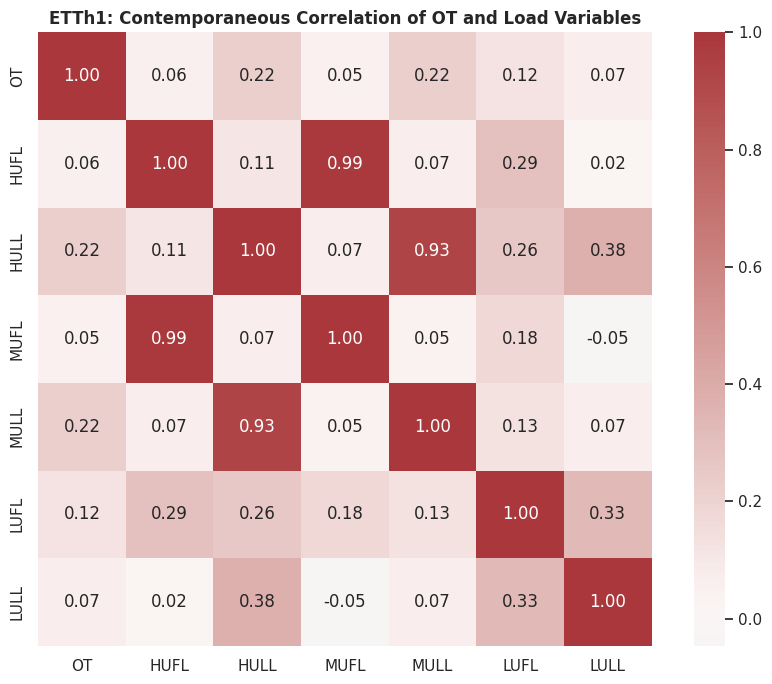

In [66]:
# OT distributions across the four datasets
fig, axes = plt.subplots(2, 1, figsize=(13, 9))
for name, frame in datasets.items():
    sns.histplot(frame["OT"].dropna(), stat="density", element="step", fill=False,
                 common_norm=False, label=name, ax=axes[0])
combined_ot = pd.concat(
    [frame[["OT"]].assign(dataset=name) for name, frame in datasets.items()],
    ignore_index=True,
)
sns.boxplot(data=combined_ot, x="OT", y="dataset", order=DATASET_NAMES, ax=axes[1])
axes[0].set(title="OT Distribution Comparison", xlabel="OT", ylabel="Density")
axes[0].legend(title="Dataset")
axes[1].set(title="OT Range and Outliers", xlabel="OT", ylabel="Dataset")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "ot_distribution_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

# ETTh1 time series and load variables
ett_h1 = datasets["ETTh1"]
load_columns = ["HUFL", "HULL", "MUFL", "MULL", "LUFL", "LULL"]
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)
ett_h1["OT"].plot(ax=axes[0], color="#c44e52", linewidth=0.8)
axes[0].set(title="ETTh1: Oil Temperature (OT)", ylabel="OT")
ett_h1[load_columns].plot(ax=axes[1], linewidth=0.7)
axes[1].set(title="ETTh1: Load Variables", ylabel="Load", xlabel="Date")
axes[1].legend(ncol=3, loc="upper right")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "etth1_time_series.png", dpi=160, bbox_inches="tight")
plt.show()

# Hour-of-day and weekday patterns
DAY_NAMES = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
hourly_profile = ett_h1.groupby(ett_h1.index.hour)[["OT"] + load_columns].mean()
weekday_profile = ett_h1.groupby(ett_h1.index.dayofweek)[["OT"] + load_columns].mean()
weekday_profile.index = DAY_NAMES
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
hourly_profile["OT"].plot(marker="o", ax=axes[0], color="#c44e52")
axes[0].set(title="Average OT by Hour of Day", xlabel="Hour (0-23)", ylabel="OT")
weekday_profile["OT"].plot(marker="o", ax=axes[1], color="#4c72b0")
axes[1].set(title="Average OT by Weekday", xlabel="Weekday", ylabel="OT")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "etth1_ot_temporal_patterns.png", dpi=160, bbox_inches="tight")
plt.show()

# Contemporaneous correlations
correlation_matrix = ett_h1[["OT"] + load_columns].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="vlag", center=0,
            square=True, ax=ax)
ax.set_title("ETTh1: Contemporaneous Correlation of OT and Load Variables")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "etth1_correlation_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

hourly_profile.to_csv(TABLE_DIR / "etth1_hourly_profile.csv")
weekday_profile.to_csv(TABLE_DIR / "etth1_weekday_profile.csv")
correlation_matrix.to_csv(TABLE_DIR / "etth1_correlation_matrix.csv")

,strongest_lag_hours,correlation,interpretation
load_variable,,,
HUFL,-129,0.173,OT leads
HULL,10,0.263,Load leads
MUFL,-129,0.175,OT leads
MULL,10,0.254,Load leads
LUFL,7,0.133,Load leads
LULL,6,0.079,Load leads


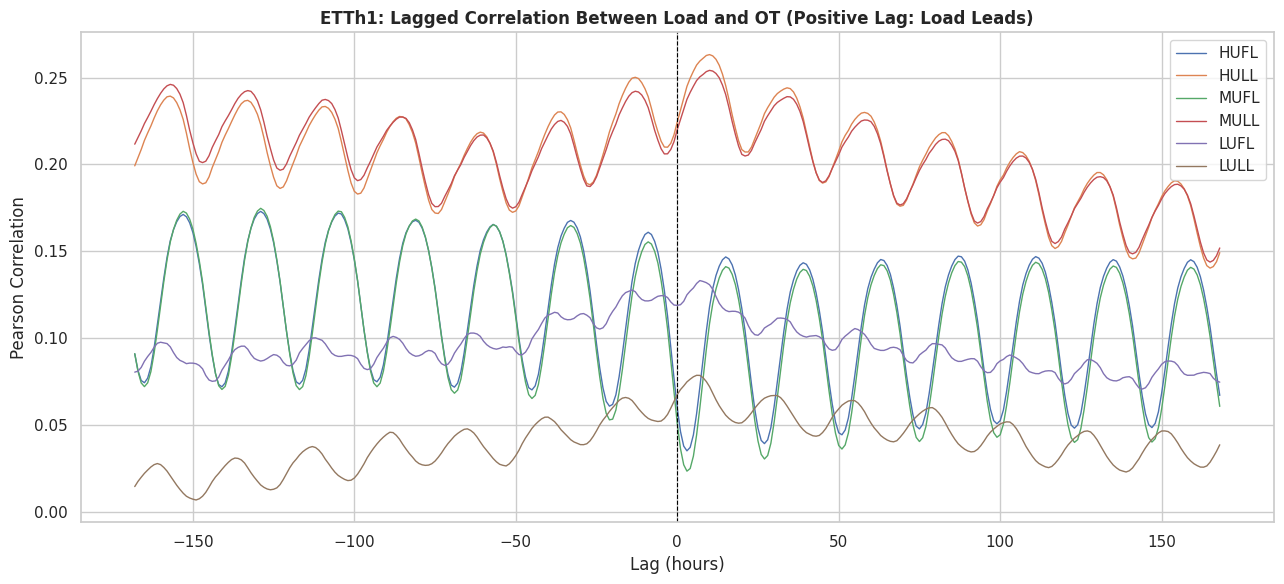

In [67]:
# A positive lag means the load variable leads OT; a negative lag means OT leads.
MAX_LAG_HOURS = 168
lag_values = range(-MAX_LAG_HOURS, MAX_LAG_HOURS + 1)
lag_correlations = pd.DataFrame(index=lag_values, columns=load_columns, dtype=float)
for lag in lag_values:
    for feature in load_columns:
        lag_correlations.loc[lag, feature] = ett_h1[feature].shift(lag).corr(ett_h1["OT"])

strongest_lags = []
for feature in load_columns:
    best_lag = lag_correlations[feature].abs().idxmax()
    strongest_lags.append({
        "load_variable": feature,
        "strongest_lag_hours": int(best_lag),
        "correlation": lag_correlations.loc[best_lag, feature],
        "interpretation": "Load leads" if best_lag > 0 else ("OT leads" if best_lag < 0 else "Simultaneous"),
    })
strongest_lags = pd.DataFrame(strongest_lags).set_index("load_variable")
display(strongest_lags.round(3))

fig, ax = plt.subplots(figsize=(13, 6))
lag_correlations.plot(ax=ax, linewidth=1)
ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
ax.set(title="ETTh1: Lagged Correlation Between Load and OT (Positive Lag: Load Leads)",
       xlabel="Lag (hours)", ylabel="Pearson Correlation")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "etth1_lagged_correlations.png", dpi=160, bbox_inches="tight")
plt.show()
lag_correlations.to_csv(TABLE_DIR / "etth1_lag_correlations.csv", index_label="Lag (hours)")
strongest_lags.to_csv(TABLE_DIR / "etth1_strongest_lags.csv")

## 8. 結果の可視化
### 日周期の時系列分解
ETTh1は1時間間隔のため、24点を1日周期として加法分解します。OTに欠損がある場合は、補完で結果を歪めないよう分解をスキップします。

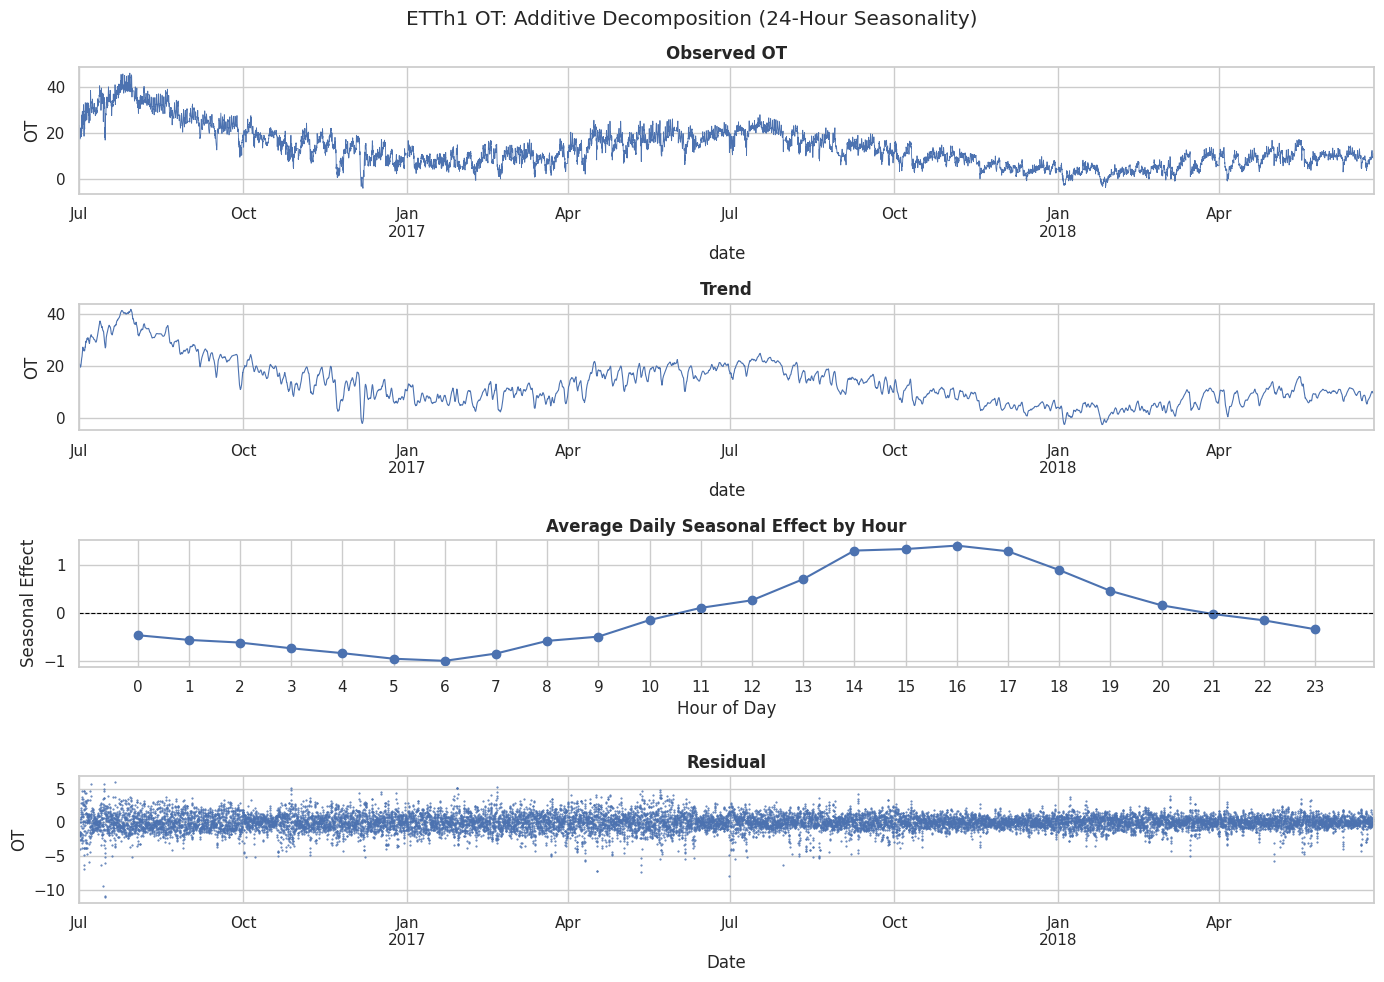

OT summary across datasets:


,OT_mean,OT_std,OT_min,OT_median,OT_max
dataset,,,,,
ETTh1,13.325,8.567,-4.080,11.396,46.007
ETTh2,26.609,11.888,-2.647,26.577,58.877
ETTm1,13.321,8.565,-4.221,11.396,46.007
ETTm2,26.610,11.887,-2.647,26.577,58.877


Strongest absolute lag correlation by load variable:


,strongest_lag_hours,correlation,interpretation
load_variable,,,
HUFL,-129,0.173,OT leads
HULL,10,0.263,Load leads
MUFL,-129,0.175,OT leads
MULL,10,0.254,Load leads
LUFL,7,0.133,Load leads
LULL,6,0.079,Load leads


In [68]:
if ett_h1["OT"].isna().any():
    print("OT contains missing values; skipping seasonal decomposition.")
else:
    from statsmodels.tsa.seasonal import seasonal_decompose

    decomposition = seasonal_decompose(ett_h1["OT"], model="additive", period=24)
    seasonal_by_hour = decomposition.seasonal.groupby(decomposition.seasonal.index.hour).mean()

    fig, axes = plt.subplots(4, 1, figsize=(14, 10))
    decomposition.observed.plot(ax=axes[0], linewidth=0.6)
    axes[0].set(title="Observed OT", ylabel="OT")

    decomposition.trend.plot(ax=axes[1], linewidth=0.8)
    axes[1].set(title="Trend", ylabel="OT")

    axes[2].plot(seasonal_by_hour.index, seasonal_by_hour.values, marker="o")
    axes[2].axhline(0, color="black", linewidth=0.8, linestyle="--")
    axes[2].set(
        title="Average Daily Seasonal Effect by Hour",
        xlabel="Hour of Day",
        ylabel="Seasonal Effect",
        xticks=range(24),
    )

    decomposition.resid.plot(ax=axes[3], marker=".", linestyle="none", markersize=1)
    axes[3].set(title="Residual", ylabel="OT", xlabel="Date")

    fig.suptitle("ETTh1 OT: Additive Decomposition (24-Hour Seasonality)")
    fig.tight_layout()
    fig.savefig(
        FIGURE_DIR / "etth1_daily_seasonal_decomposition.png",
        dpi=160,
        bbox_inches="tight",
    )
    plt.show()

print("OT summary across datasets:")
display(dataset_summary.round(3))
print("Strongest absolute lag correlation by load variable:")
display(strongest_lags.round(3))

図表を見て、データセット間のOT分布差、ETTh1のトレンド・日内変動、負荷とOTの関連や先行時間を観察事実として記録します。ラグ相関や周期性だけから因果関係を断定しないでください。将来予測を行う場合は、時系列順の評価分割と単純ベースラインとの比較が必要です。

## 9. 成果物の保存とエクスポート
集計表・分析表はCSV、図表はPNGとしてDriveの`eda_output`に保存済みです。以下でフォルダーをZIP化します。

In [69]:
quality_report.to_csv(TABLE_DIR / "data_quality.csv")
dataset_summary.to_csv(TABLE_DIR / "dataset_summary.csv")

import shutil

zip_path = shutil.make_archive(
    str(DRIVE_ROOT / "ett_eda_outputs"),
    "zip",
    root_dir=OUTPUT_DIR,
)
print("EDA output folder:", OUTPUT_DIR)
print("ZIP archive:", zip_path)
print("Saved files:")
for output_path in sorted(OUTPUT_DIR.rglob("*")):
    if output_path.is_file():
        print("-", output_path.relative_to(DRIVE_ROOT))

EDA output folder: /content/drive/Othercomputers/マイ Mac/assignment-main/eda_output
ZIP archive: /content/drive/Othercomputers/マイ Mac/assignment-main/ett_eda_outputs.zip
Saved files:
- eda_output/figures/etth1_correlation_heatmap.png
- eda_output/figures/etth1_daily_seasonal_decomposition.png
- eda_output/figures/etth1_lagged_correlations.png
- eda_output/figures/etth1_ot_temporal_patterns.png
- eda_output/figures/etth1_time_series.png
- eda_output/figures/ot_distribution_comparison.png
- eda_output/tables/data_quality.csv
- eda_output/tables/dataset_summary.csv
- eda_output/tables/etth1_correlation_matrix.csv
- eda_output/tables/etth1_hourly_profile.csv
- eda_output/tables/etth1_lag_correlations.csv
- eda_output/tables/etth1_strongest_lags.csv
- eda_output/tables/etth1_weekday_profile.csv
